Below is the following code used to get the data vidualisation of mangroves in gained and lossed in Guyana from 1984-2023, 2004-2023, and 2019-2023. 

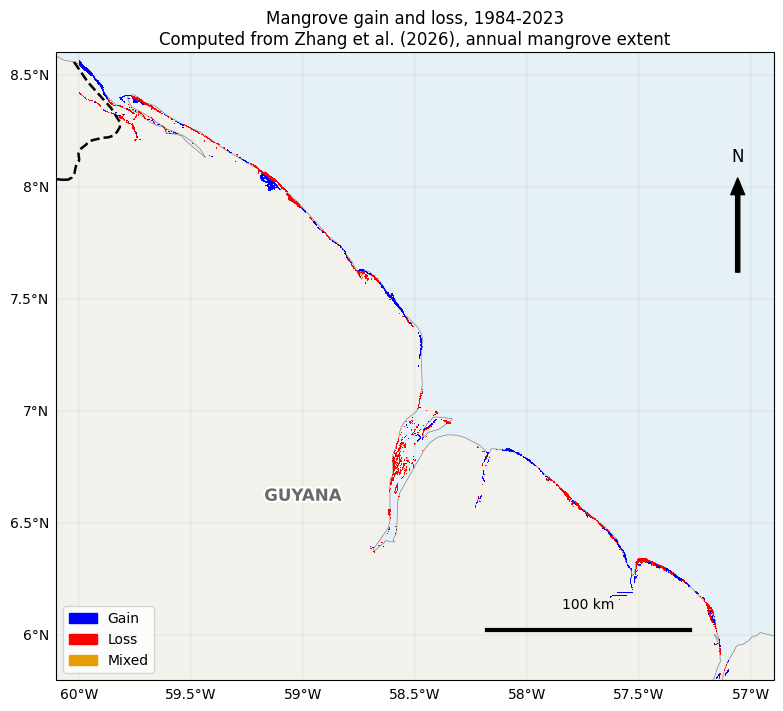

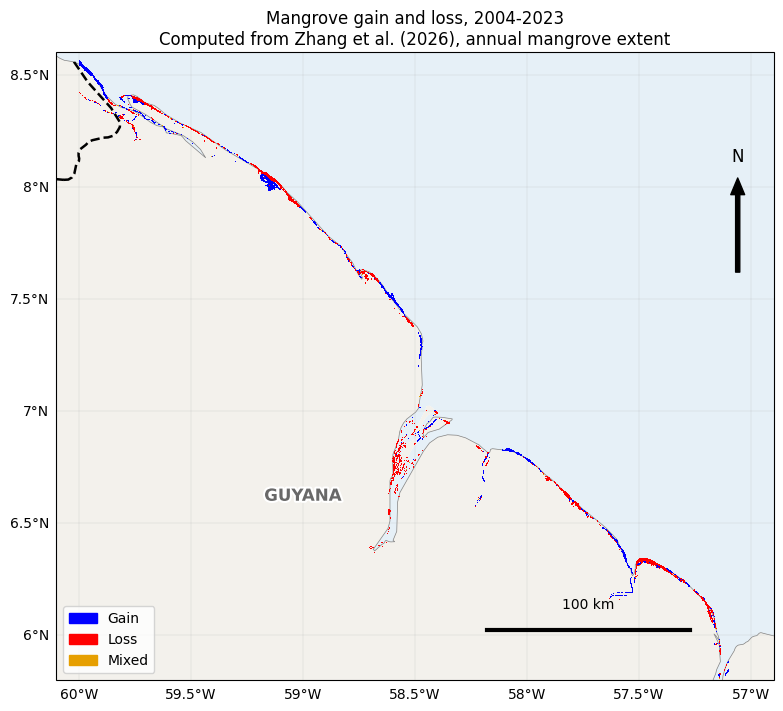

In [ ]:
import rasterio
from rasterio.windows import from_bounds
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import matplotlib.patheffects as pe

# Settings
BOUNDS = (-60.1, 5.8, -56.9, 8.6)  # west, south, east, north (Guyana)

# Gain/loss: computed in Google Earth Engine from the annual mangrove extent maps
# of Zhang et al. (2026), CGMD-Extent30; exported as GeoTIFFs.
CHANGE_FILES = {
    "2004-2023": "guyana_mangrove_change_2004_2023.tif",
}

# Helpers 
def read_window(path, bounds=BOUNDS):
    """Read only the part of a raster inside the bounding box
    (trimmed to the file's own edges so the image isn't stretched)."""
    west, south, east, north = bounds
    with rasterio.open(path) as src:
        b = src.bounds
        west, east = max(west, b.left), min(east, b.right)
        south, north = max(south, b.bottom), min(north, b.top)
        win = from_bounds(west, south, east, north, src.transform)
        win = win.round_offsets().round_lengths()
        data = src.read(1, window=win).astype("float32")
        left, bottom, right, top = src.window_bounds(win)
    return data, [left, right, bottom, top]

def add_scale_bar(ax, length_km=100, location=(0.72, 0.08)):
    """Draw a scale bar in km, sized for the middle latitude of the map."""
    west, east, south, north = ax.get_extent(crs=ccrs.PlateCarree())
    lat_mid = (south + north) / 2
    length_deg = length_km / (111.32 * np.cos(np.radians(lat_mid)))
    x0 = west + location[0] * (east - west)
    y0 = south + location[1] * (north - south)
    ax.plot([x0, x0 + length_deg], [y0, y0], color="black", linewidth=3,
            transform=ccrs.PlateCarree(), zorder=10)
    ax.text(x0 + length_deg / 2, y0 + 0.03 * (north - south), f"{length_km} km",
            ha="center", va="bottom", transform=ccrs.PlateCarree(), zorder=10)

def add_north_arrow(ax, x=0.95, y=0.80, length=0.15):
    """Draw a north arrow in axes coordinates (0 to 1)."""
    ax.annotate("", xy=(x, y), xytext=(x, y - length), xycoords="axes fraction",
                arrowprops=dict(facecolor="black", width=3, headwidth=10), zorder=10)
    ax.text(x, y + 0.02, "N", ha="center", va="bottom",
            transform=ax.transAxes, fontsize=12, zorder=10)

COUNTRY_LABELS = {         
    "SURINAME": (-55.6, 4.8),
    "FRENCH GUIANA": (-53.1, 4.55),
    "BRAZIL": (-51.4, 4.1),
    "GUYANA": (-59.0, 6.6),     
}

def coarsen_change(change, extent, factor=15):
    """Aggregate 30 m gain/loss to factor x factor blocks (~450 m at 15) for display only.
    A block shows the dominant change type among its changed pixels."""
    left, right, bottom, top = extent
    h, w = change.shape
    xres, yres = (right - left) / w, (top - bottom) / h
    h2, w2 = (h // factor) * factor, (w // factor) * factor
    blocks = change[:h2, :w2].reshape(h2 // factor, factor, w2 // factor, factor)
    gain = (blocks == 1).sum(axis=(1, 3))
    loss = (blocks == 2).sum(axis=(1, 3))
    out = np.full(gain.shape, np.nan, dtype="float32")
    out[gain > loss] = 1
    out[loss > gain] = 2
    out[(gain == loss) & (gain > 0)] = 3          # mixed
    new_extent = [left, left + w2 * xres, top - h2 * yres, top]
    return out, new_extent

def style_map(ax, bounds=BOUNDS):
    west, south, east, north = bounds
    ax.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.OCEAN.with_scale("10m"), facecolor="#e6f0f7", zorder=0)
    ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor="#f3f1ec", zorder=0)
    ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.5, edgecolor="gray")
    borders_10m = cfeature.NaturalEarthFeature(
        "cultural", "admin_0_boundary_lines_land", "10m",
        edgecolor="black", facecolor="none")
    ax.add_feature(borders_10m, linewidth=1.8, linestyle="--", zorder=9)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False
    add_scale_bar(ax, location=(0.60, 0.08))      # pulled in from the edge
    add_north_arrow(ax)
    add_country_labels(ax)

def plot_change(period, factor=15):
    change, change_extent = read_window(CHANGE_FILES[period])
    change, change_extent = coarsen_change(change, change_extent, factor)

    fig, ax = plt.subplots(
        figsize=(8, 7), layout="constrained",      # closer to the box's shape
        subplot_kw={"projection": ccrs.PlateCarree()})
    ax.imshow(change, extent=change_extent, origin="upper",
              cmap=ListedColormap(["blue", "red", "#E69F00"]), vmin=1, vmax=3,
              transform=ccrs.PlateCarree(), interpolation="nearest", zorder=5)
    ax.set_title(f"Mangrove gain and loss, {period}\n"
                 "Computed from Zhang et al. (2026), annual mangrove extent")
    ax.legend(handles=[Patch(color="blue", label="Gain"),
                       Patch(color="red", label="Loss"),
                       Patch(color="#E69F00", label="Mixed")],
              loc="lower left")
    style_map(ax)
    fig.savefig(f"mangrove_gain_loss_{period.replace('-', '_')}.png",
                dpi=200, bbox_inches="tight")
    plt.show()

# --- Make both figures ---
for period in CHANGE_FILES:
    plot_change(period)

In [8]:
import rasterio
with rasterio.open("guyana_mangrove_change_2004_2023.tif") as src:
    print(src.crs)
    print(src.bounds)

EPSG:4326
BoundingBox(left=-60.000004962325846, bottom=5.799792968860867, right=-57.0999737306028, top=8.702788641021513)


In [9]:
print(src.bounds)

BoundingBox(left=-60.000004962325846, bottom=5.799792968860867, right=-57.0999737306028, top=8.702788641021513)


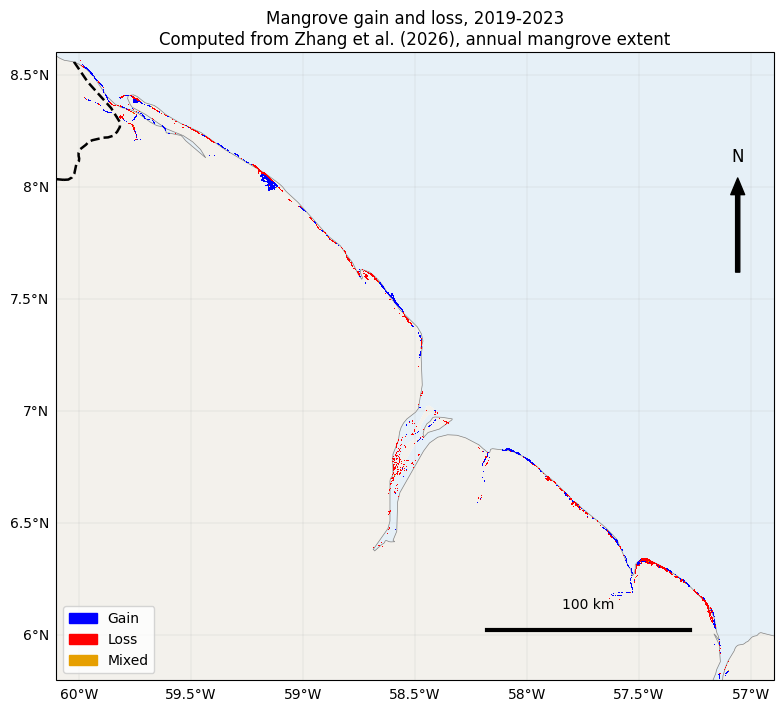

In [2]:
import rasterio
from rasterio.windows import from_bounds
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import matplotlib.patheffects as pe

# Settings
BOUNDS = (-60.1, 5.8, -56.9, 8.6)  # west, south, east, north (Guyana)

# Gain/loss: computed in Google Earth Engine from the annual mangrove extent maps
# of Zhang et al. (2026), CGMD-Extent30; exported as GeoTIFFs.
CHANGE_FILES = {
    "2019-2023": "guyana_mangrove_change_2019_2023.tif",
}

# Helpers 
def read_window(path, bounds=BOUNDS):
    """Read only the part of a raster inside the bounding box
    (trimmed to the file's own edges so the image isn't stretched)."""
    west, south, east, north = bounds
    with rasterio.open(path) as src:
        b = src.bounds
        west, east = max(west, b.left), min(east, b.right)
        south, north = max(south, b.bottom), min(north, b.top)
        win = from_bounds(west, south, east, north, src.transform)
        win = win.round_offsets().round_lengths()
        data = src.read(1, window=win).astype("float32")
        left, bottom, right, top = src.window_bounds(win)
    return data, [left, right, bottom, top]

def add_scale_bar(ax, length_km=100, location=(0.72, 0.08)):
    """Draw a scale bar in km, sized for the middle latitude of the map."""
    west, east, south, north = ax.get_extent(crs=ccrs.PlateCarree())
    lat_mid = (south + north) / 2
    length_deg = length_km / (111.32 * np.cos(np.radians(lat_mid)))
    x0 = west + location[0] * (east - west)
    y0 = south + location[1] * (north - south)
    ax.plot([x0, x0 + length_deg], [y0, y0], color="black", linewidth=3,
            transform=ccrs.PlateCarree(), zorder=10)
    ax.text(x0 + length_deg / 2, y0 + 0.03 * (north - south), f"{length_km} km",
            ha="center", va="bottom", transform=ccrs.PlateCarree(), zorder=10)

def add_north_arrow(ax, x=0.95, y=0.80, length=0.15):
    """Draw a north arrow in axes coordinates (0 to 1)."""
    ax.annotate("", xy=(x, y), xytext=(x, y - length), xycoords="axes fraction",
                arrowprops=dict(facecolor="black", width=3, headwidth=10), zorder=10)
    ax.text(x, y + 0.02, "N", ha="center", va="bottom",
            transform=ax.transAxes, fontsize=12, zorder=10)

COUNTRY_LABELS = {         
    "SURINAME": (-55.6, 4.8),
    "FRENCH GUIANA": (-53.1, 4.55),
    "BRAZIL": (-51.4, 4.1),
    "GUYANA": (-59.0, 6.6),     
}

def coarsen_change(change, extent, factor=15):
    """Aggregate 30 m gain/loss to factor x factor blocks (~450 m at 15) for display only.
    A block shows the dominant change type among its changed pixels."""
    left, right, bottom, top = extent
    h, w = change.shape
    xres, yres = (right - left) / w, (top - bottom) / h
    h2, w2 = (h // factor) * factor, (w // factor) * factor
    blocks = change[:h2, :w2].reshape(h2 // factor, factor, w2 // factor, factor)
    gain = (blocks == 1).sum(axis=(1, 3))
    loss = (blocks == 2).sum(axis=(1, 3))
    out = np.full(gain.shape, np.nan, dtype="float32")
    out[gain > loss] = 1
    out[loss > gain] = 2
    out[(gain == loss) & (gain > 0)] = 3          # mixed
    new_extent = [left, left + w2 * xres, top - h2 * yres, top]
    return out, new_extent

def style_map(ax, bounds=BOUNDS):
    west, south, east, north = bounds
    ax.set_extent([west, east, south, north], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.OCEAN.with_scale("10m"), facecolor="#e6f0f7", zorder=0)
    ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor="#f3f1ec", zorder=0)
    ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.5, edgecolor="gray")
    borders_10m = cfeature.NaturalEarthFeature(
        "cultural", "admin_0_boundary_lines_land", "10m",
        edgecolor="black", facecolor="none")
    ax.add_feature(borders_10m, linewidth=1.8, linestyle="--", zorder=9)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False
    add_scale_bar(ax, location=(0.60, 0.08))      # pulled in from the edge
    add_north_arrow(ax)
    #add_country_labels(ax)

def plot_change(period, factor=15):
    change, change_extent = read_window(CHANGE_FILES[period])
    change, change_extent = coarsen_change(change, change_extent, factor)

    fig, ax = plt.subplots(
        figsize=(8, 7), layout="constrained",      # closer to the box's shape
        subplot_kw={"projection": ccrs.PlateCarree()})
    ax.imshow(change, extent=change_extent, origin="upper",
              cmap=ListedColormap(["blue", "red", "#E69F00"]), vmin=1, vmax=3,
              transform=ccrs.PlateCarree(), interpolation="nearest", zorder=5)
    ax.set_title(f"Mangrove gain and loss, {period}\n"
                 "Computed from Zhang et al. (2026), annual mangrove extent")
    ax.legend(handles=[Patch(color="blue", label="Gain"),
                       Patch(color="red", label="Loss"),
                       Patch(color="#E69F00", label="Mixed")],
              loc="lower left")
    style_map(ax)
    fig.savefig(f"mangrove_gain_loss_{period.replace('-', '_')}.png",
                dpi=200, bbox_inches="tight")
    plt.show()

# Make both figures
for period in CHANGE_FILES:
    plot_change(period)

For this project we will be focusing on mangrove gain and loss from 2019-2023. 